# Programmation Python  pour les mathématiques

**Julien Guillod**, [Sorbonne Université](http://www.sorbonne-universite.fr/),
Licence <a href="https://creativecommons.org/licenses/by-nc-nd/4.0/">CC BY-NC-ND</a>

L'entier des chapitres est disponible au format
[HTML](https://python.guillod.org/) et [PDF](https://python.guillod.org/python.pdf).
Ce notebook peut également être exécuté sur [GESIS](https://notebooks.gesis.org/binder/v2/gh/guillod/python/master?urlpath=lab/tree/chap03.ipynb).

# 3 Structures homogènes

<div id="ch:numpy"></div>

Les structures de données par défaut de Python permettent de gérer des données hétérogènes (par exemple des entiers et des chaînes de caractères). Cette particularité fait que les structures de données Python sont extrêmement flexibles, au détriment de la performance. En effet vu que des données hétérogènes doivent pouvoir être supportées, il n'est pas possible d'allouer une plage de mémoire fixe pour une structure de données, ce qui ralentit son utilisation.  Particulièrement en mathématiques, il apparaît très régulièrement des ensembles de données homogènes de tailles fixes (liste d'entiers, vecteurs réels ou complexes, matrices...). Le module Numpy définit le type `ndarray` qui est optimisé pour de telles structures de données homogènes de tailles fixes. La documentation de Numpy est disponible [ici](https://numpy.org/doc/stable/).

Pour charger le module Numpy, il est d'usage de procéder ainsi:

In [23]:
import numpy as np

**Concepts abordés:**

* tableau de données homogènes

* slicing

* opérations vectorielles

* indexage et sélection

* représentations graphiques

* optimisation par parallélisation

# Exercice 3.1: Introduction à Numpy

**Création.**
La taille et le type des éléments d'un tableau Numpy doivent être connus à l'avance. La première façon de créer un tableau Numpy est de construire un tableau rempli de zéros en spécifiant la taille et le type:

In [24]:
array0 = np.zeros(3, dtype=int) # vecteur de 3 entiers
array1 = np.zeros((2,4), dtype=float) # tableau de flottants de taille 2x4
array2 = np.zeros((2,2), dtype=complex) # matrice carrée complexe de taille 2x2
array3 = np.zeros((5,6,4)) # tableau tridimensionnel de flottants

La seconde façon est de passer directement les données:

In [25]:
array4 = np.array([1,4,5]) # vecteur d'entiers (1,4,5)
array5 = np.array([[1.1,2.2,3.3,4.4],[1,2,3,4]]) # matrice de taille 2x4 de flottants
array6 = np.array([[1+1j,0.4],[3,1.5]]) # matrice complexe de taille 2x2

array6

array([[1. +1.j, 0.4+0.j],
       [3. +0.j, 1.5+0.j]])

Numpy va alors déterminer lui-même le type et la taille du tableau. À noter qu'il est possible de forcer le type:

In [26]:
array0 = np.array([1,4,5], dtype=complex) # vecteur de complexes

Le type des éléments du tableau Numpy `array1` peut être déterminé par `array1.dtype`. La taille de ce tableau est donnée par `array1.shape`.
Les commandes suivantes permettent d'accéder aux éléments des tableaux :

In [27]:
array4[1] # retourne 4
array5[1,3] # retourne 4.0

4.0

À noter que les indices commencent à 0 et non pas à 1.
Les tableaux Numpy sont mutables dans le sens où les données peuvent être modifiées mais en conservant le même type et la même taille:

In [28]:
array0[1] = 4
array1[1,3] = 3.3
array3[3,4,2] = 3

In [57]:
array3[3,4,:1]

array([0.])

**Slicing.**
Le slicing permet d'accéder à certaines parties d'un tableau:

In [30]:
array4[2:3] # retourne les éléments d'indices compris entre 2 (inclu) et 3 (exclu)
array1[0,:] # retourne la première ligne de array1
array1[:,-1] # retourne la dernière colonne de array1
array3[3,3:5,1:4] # retourne la sous-matrice correspondante

array([[0., 0., 0.],
       [0., 3., 0.]])

In [63]:
import numpy as np

x = np.array([[[1,2,4],[3,4,5]],[[1,2,3], [9,8,7]]])
x[1][1,:1]

array([9])

**Itération.**
Il est possible d'itérer un tableau sur sa première dimension, par exemple pour retourner la somme des lignes:

In [32]:
print(array5)

for i in array5:
    print(np.sum(i))

[[1.1 2.2 3.3 4.4]
 [1.  2.  3.  4. ]]
11.0
10.0


**a)**
Étudier la documentation de la fonction `arange` et utiliser cette fonction pour générer les vecteurs (5,6,7,8,9) et (3,5,7,9).

**Indication:**
La documentation de la fonction `arange` est disponible [ici](https://numpy.org/doc/stable/reference/generated/numpy.arange.html).

In [33]:
u = np.arange(5,10)
v = np.arange(3,10,2)

print(u,v)

[5 6 7 8 9] [3 5 7 9]


**b)**
Étudier la documentation de la fonction `linspace` et l'utiliser pour générer 10 points équidistribués dans l'intervalle $[2,5]$.

In [34]:
u = np.linspace(2, 5, num=10)
u

array([2.        , 2.33333333, 2.66666667, 3.        , 3.33333333,
       3.66666667, 4.        , 4.33333333, 4.66666667, 5.        ])

**c)**
Lire la documentation de la fonction `reshape` et effectuer successivement les transformations suivantes:

$$
(1,2,3,4,5,6)\to\begin{pmatrix}1 & 2\\ 
3 & 4\\ 
5 & 6
\end{pmatrix}\to\begin{pmatrix}1 & 2 & 3\\ 
4 & 5 & 6
\end{pmatrix}\to\begin{pmatrix}1 & 4\\ 
2 & 5\\ 
3 & 6
\end{pmatrix}
$$

In [66]:
a = np.arange(1,7).reshape((3, 2))
b = np.reshape(a,(2,3))
c = np.reshape(b.flat,(3,2),"F")

print(np.arange(1,7),'\n ==> \n',a,'\n ==> \n ',b,' \n ==> \n',c)


[1 2 3 4 5 6] 
 ==> 
 [[1 2]
 [3 4]
 [5 6]] 
 ==> 
  [[1 2 3]
 [4 5 6]]  
 ==> 
 [[1 4]
 [2 5]
 [3 6]]


# Exercice 3.2: Opérations sur les tableaux

Les opérations arithmétiques de base sur les tableaux Numpy sont effectuées éléments par éléments:

In [36]:
mat1 = np.array([[1,2.5,3],[5,6.1,8],[3,2,5]])
mat2 = np.array([[1,0.5,0],[0,0.9,8],[2,0,0]])
mat1 + mat2 # retourne la somme élément par élément
mat1 * mat2 # retourne le produit élément par élément (pas le produit matriciel)
10*mat1**2 # retourne 10 fois le carré des éléments de mat1

array([[ 10. ,  62.5,  90. ],
       [250. , 372.1, 640. ],
       [ 90. ,  40. , 250. ]])

La plupart des fonctions mathématiques définies par Numpy (voir [ici](https://numpy.org/doc/stable/reference/routines.math.html)) sont aussi effectuées éléments par éléments:

In [37]:
np.cos(mat1) # retourne le cosinus élément par élément de mat1
np.exp(mat1) # retourne l'exponentielle élément par élément de mat1

array([[2.71828183e+00, 1.21824940e+01, 2.00855369e+01],
       [1.48413159e+02, 4.45857770e+02, 2.98095799e+03],
       [2.00855369e+01, 7.38905610e+00, 1.48413159e+02]])

Le produit matriciel peut être effectué d'une des trois façons suivantes, mais la dernière méthode est recommandée pour sa lisibilité (surtout quand plusieurs produits matriciels sont effectués):

In [38]:
np.dot(mat1,mat2)
mat1.dot(mat2)
mat1 @ mat2

array([[ 7.  ,  2.75, 20.  ],
       [21.  ,  7.99, 48.8 ],
       [13.  ,  3.3 , 16.  ]])

**a)**
Donné un vecteur $(v_0,v_1,\dots,v_{n-1})\in\mathbb{R}^n$ la dérivée discrète de ce vecteur est définie par le vecteur $(d_0,d_1,\dots,d_{n-2})\in\mathbb{R}^{n-1}$ donné par $d_i = v_{i+1}-v_{i}$ pour $i=0,1,\dots,n-2$.

Écrire une fonction `diff_list` qui calcule la dérivée discrète d'une liste et une fonction `diff_np` qui fait la même opération mais sur des vecteurs Numpy en utilisant le slicing.

In [39]:
def diff_list(u):
    return [u[i+1]-u[i] for i in range(len(u)-1)]

a = [1,5,4,3]
diff_list(a)

[4, -1, -1]

In [40]:
def diff_np(u):
    return u[1:]-u[:-1]

b = np.array(a)
diff_np(b)

array([ 4, -1, -1])

**b)**
Soit `a_list` et `a_np` respectivement une liste et un tableau de 1 000 éléments tirés au hasard dans l'intervalle [0,1]:

In [41]:
a_list = [np.random.random() for _ in range(1000)]
a_np = np.random.random(1000)

Comparer le temps d'exécution de `diff_list(a_list)` et de `diff_np(a_np)`.

**Indication:**
Dans Jupyter Lab, il est très facile de déterminer le temps pris par une cellule pour s'évaluer, il suffit de commencer la cellule par `%%time`, par exemple:

In [42]:
%%timeit
result = diff_list(a_list)

192 µs ± 38.4 µs per loop (mean ± std. dev. of 7 runs, 10,000 loops each)


In [43]:
a_array = np.array(a_list)

In [44]:
%%timeit
result = diff_np(a_array)

1.92 µs ± 516 ns per loop (mean ± std. dev. of 7 runs, 100,000 loops each)


####  Il est immédiat que la méthode utilisant les arrays soit plus rapide que la méthode par les listes

Pour évaluer la cellule à de multiples reprises et faire une moyenne sur le temps d'exécution afin d'obtenir un résultat plus précis, remplacer `%%time` par `%%timeit`. La documentation est disponible [ici](https://ipython.readthedocs.io/en/stable/interactive/magics.html#magic-timeit).

**Réponse:**
Le temps d'exécution avec les tableaux Numpy devrait être approximativement 50 à 100 fois plus rapide qu'avec les listes !

# Exercice 3.3: Représentations graphiques

Le module `matplotlib` permet de faire des représentations graphiques très variées. Pour l'utiliser, il est d'usage de l'importer ainsi:

In [45]:
%matplotlib inline
import matplotlib.pyplot as plt

A noter que la première ligne permet de représenter les graphiques directement dans Jupyter Lab, mais n'est pas indispensable.

Par exemple la fonction `plot` peut être utilisée pour représenter la fonction $x^2$:

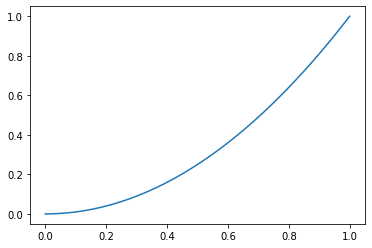

In [46]:
x = np.linspace(0,1,50)
y = x**2
plt.plot(x,y)
plt.show()

Afin de définir une jolie figure pouvant être exportée, la syntaxe est la suivante:

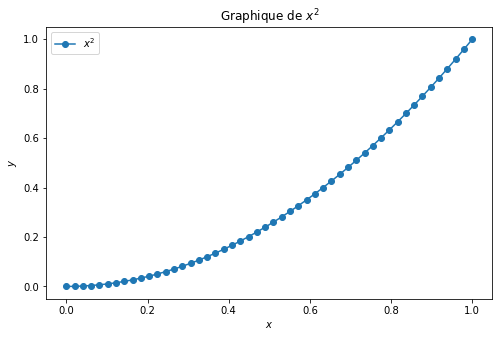

In [47]:
plt.figure(figsize=(8,5)) # taille de la figure (en inches)
plt.title(r'Graphique de $x^2$') # titre de la figure (du code LaTeX peut être inclus)
plt.xlabel(r'$x$') # titre de l'axe horizontal
plt.ylabel(r'$y$') # titre de l'axe vertical
plt.plot(x, y, marker='o', label=r"$x^2$") # légende
plt.legend() # affiche la légende
plt.savefig("test.pdf") # exporte la figure en PDF
plt.savefig("test.png", dpi=100) # exporte la figure en PNG
plt.show()

<center><img src="https://python.guillod.org/fig/matplotlib-x2.png" style="width:90%;max-width:800px;"></center>

La documentation de Matplotlib est disponible [ici](https://matplotlib.org/users/index.html).

**a)**
Représenter graphiquement sur la même figure les fonctions $\sin(kx)$ et $\cos(kx)$ pour $k=1,2,3$ pour $x\in[0,2\pi]$. Faire en sorte que les graduations sur l'axe horizontal soient tous les $\frac{\pi}{2}$:

<center><img src="https://python.guillod.org/fig/matplotlib-sincos.png" style="width:90%;max-width:800px;"></center>

**Indication:**
Utiliser la fonction `xticks` ou les fonctions `set_xticks` et `set_xticklabels` décrites [ici](https://matplotlib.org/api/_as_gen/matplotlib.pyplot.xticks.html).

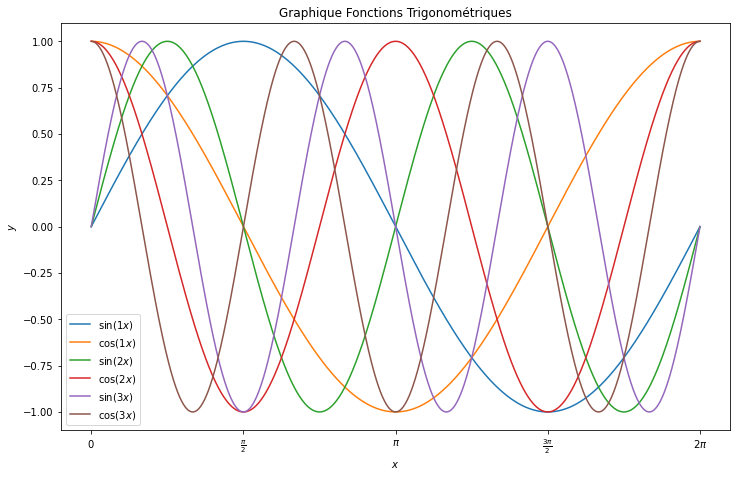

In [48]:
x = np.linspace(0,2*np.pi,1000)
plt.figure(figsize=(12,7.5)) # taille de la figure (en inches)
plt.title(r'Graphique Fonctions Trigonométriques') # titre de la figure (du code LaTeX peut être inclus)
plt.xlabel(r'$x$') # titre de l'axe horizontal
plt.ylabel(r'$y$') # titre de l'axe vertical
plt.xticks([0,np.pi/2,np.pi,3*np.pi/2,2*np.pi],
           [r'$0$',r'$\frac{\pi}{2}$',r'$\pi$',r'$\frac{3\pi}{2}$',r'$2\pi$'])

for i in range(1,4):
    plt.plot(x,np.sin(i*x),label = r'$\sin({}x)$'.format(i))
    plt.plot(x,np.cos(i*x),label = r'$\cos({}x)$'.format(i))

plt.legend() # affiche la légende
plt.show() 

**b)**
Regarder l'aide de la fonction `imshow` et l'utiliser pour représenter graphiquement une matrice de nombres aléatoires dans $[0,1]$ de taille $10\times10$:

<center><img src="https://python.guillod.org/fig/matplotlib-imshow.png" style="width:90%;max-width:400px;"></center>

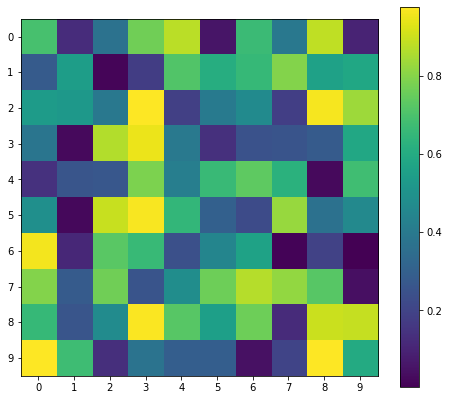

In [49]:
M=np.random.rand(10,10) # retourne une matrice 10x10 de nombres aléatoires dans [0,1[
plt.figure(figsize=(8,7))
plt.imshow(M)
plt.colorbar()
plt.xticks(range(M.shape[0]))
plt.yticks(range(M.shape[1]))
plt.show()



**c)**
<span style="color:red">!</span> Représenter graphiquement la fonction $f(x,y) = \frac{-y}{5} + e^{-x^2-y^2}$ pour $x\in[-3,3]$ et $y\in[-3,3]$ en densité et avec des courbes de niveau:

<center><img src="https://python.guillod.org/fig/matplotlib-2d.png" style="width:90%;max-width:900px;"></center>

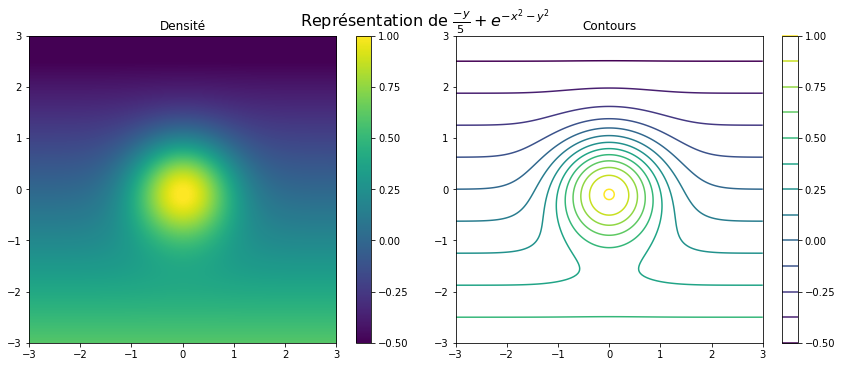

In [50]:
x = np.linspace(-3.0,3.0,200)
y = np.linspace(-3.0,3.0,200)

X,Y = np.meshgrid(x,y)
F = -Y/5 + np.exp(-X**2 - Y**2)

fig = plt.figure(figsize=(12,5))
fig.suptitle(r'Représentation de $\frac{-y}{5}+e^{-x^2 -y^2}$', fontsize=16)

sub = fig.add_subplot(1,2,1)
sub.set_title('Densité')

im  = sub.imshow(F,extent=[-3,3,-3,3],vmin=-0.5,vmax=1,interpolation='bilinear',origin='lower')
plt.colorbar(im,ax=sub,ticks=np.linspace(-0.5,1,7))

sub = fig.add_subplot(1,2,2)
sub.set_title('Contours')
im = sub.contour(X,Y,F, levels=np.linspace(-0.5,1,13))
plt.colorbar(im,ax=sub,ticks=np.linspace(-0.5,1,7))
sub.set_aspect('equal')

fig.tight_layout()
fig.subplots_adjust(top=0.9)
plt.show()

**d)**
<span style="color:red">!!</span> Regarder les exemples disponibles [ici](https://matplotlib.org/tutorials/introductory/sample_plots.html) et en choisir deux à comprendre et à modifier.

En premier exemple on retravaille la colormap 3D disponible ici :
https://matplotlib.org/3.4.3/gallery/mplot3d/surface3d.html
En y changeant la fonction, le domaine de définition (sur X) et les couleurs afin que ce soit plus compréhensible. Enfin, on aura surtout utilisé la méthode subplot afin de pouvoir offrir deux visualisation 3D de la fonction que l'on a choisie. 

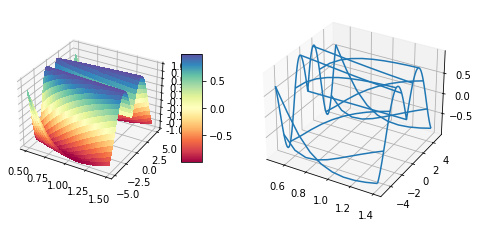

In [51]:
from matplotlib import cm
from matplotlib.ticker import LinearLocator

fig = fig = plt.figure(figsize=plt.figaspect(0.5))
 
ax = fig.add_subplot(1, 2, 1, projection='3d')

# Make data.
Y = np.arange(-5, 5, 0.01)
X = np.arange(0.5, 1.5, 0.01)
X, Y = np.meshgrid(X, Y)
R = np.sqrt((Y**2)/X)
Z= np.sin(R)

# Plot the surface.
surf = ax.plot_surface(X, Y, Z, cmap=cm.Spectral,
                       linewidth=0, antialiased=False)

# Customize the z axis.
ax.set_zlim(-1.01, 1.01)
ax.zaxis.set_major_locator(LinearLocator(10))
# A StrMethodFormatter is used automatically
ax.zaxis.set_major_formatter('{x:.02f}')

# Add a color bar which maps values to colors.
fig.colorbar(surf, shrink=0.5, aspect=5)

ax = fig.add_subplot(1, 2, 2, projection='3d')

# plot a 3D wireframe like in the example mplot3d/wire3d_demo
Y = np.arange(-5, 5, 0.1)
X = np.arange(0.5, 1.5, 0.1)
X, Y = np.meshgrid(X, Y)
R = np.sqrt((Y**2)/X)
Z= np.sin(R)

ax.plot_wireframe(X, Y, Z, rstride=10, cstride=10)

plt.show()


On reprend l'exemple https://matplotlib.org/stable/gallery/lines_bars_and_markers/fill.html#sphx-glr-gallery-lines-bars-and-markers-fill-py 
En jouant avec les paramètres numériques de la fonction koch_snowflake, on définit une fonction koch_bowie,
et en modifiant la mise en page et les couleurs du plot, on peut y retrouver quelques liens avec le style du Musicien David Bowie

In [52]:
def koch_bowie(order, scale=10):
    """
    Return two lists x, y of point coordinates of the Koch snowflake.

    Parameters
    ----------
    order : int
        The recursion depth.
    scale : float
        The extent of the snowflake (edge length of the base triangle).
    """
    def _koch_snowflake_complex(order):
        if order == 0:
            # initial triangle
            angles = np.array([0, 120, 240]) + 90
            return scale / np.sqrt(3) * np.exp(np.deg2rad(angles) * 1j)
        else:
            ZR = 0.2 - 0.7j * np.sqrt(5) / 4

            p1 = _koch_snowflake_complex(order - 1)  # start points
            p2 = np.roll(p1, shift=-1)  # end points
            dp = p2 - p1  # connection vectors

            new_points = np.empty(len(p1) * 4, dtype=np.complex128)
            new_points[::4] = p1
            new_points[1::4] = p1 + dp / 2
            new_points[2::4] = p1 + dp * ZR
            new_points[3::4] = p1 + dp / 3 * 7
            return new_points

    points = _koch_snowflake_complex(order)
    x, y = points.real, points.imag
    return x, y


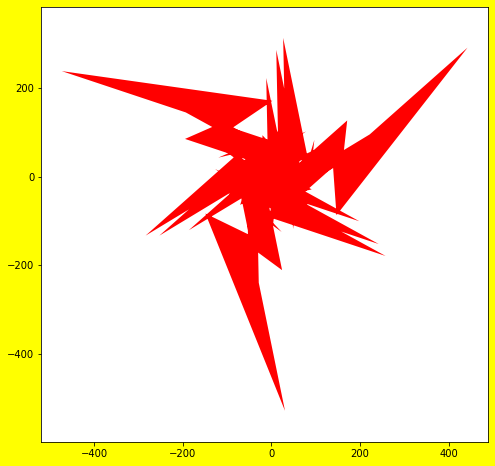

In [68]:
x, y = koch_bowie(order=5)

plt.figure(figsize=(8, 8),facecolor='yellow')
plt.axis('equal')
plt.fill(x, y,'r')
plt.show()

# Exercice 3.4: <span style="color:red">!</span> Indexage de tableaux

Le slicing permet de sélectionner des blocs dans un tableau, mais il est également possible de sélectionner des éléments disparates en utilisant un tableau comme indexage:

In [ ]:
a = np.arange(12)**2 # tableau des carrés parfaits
i = np.array([1,3,8,5]) # tableau d'indices
a[i] # tableau des éléments de a aux places i

array([ 1,  9, 64, 25])

À noter qu'il est également possible d'indexer par un tableau de dimension supérieure. Le résultat est alors un tableau de la même forme que l'index:

In [ ]:
j = np.array([[3,4],[9,7]]) # tableau bidimensionnel d'indices
a[j] # sélectionne les éléments de a avec les indices j

array([[ 9, 16],
       [81, 49]])

Pour un tableau à plusieurs dimensions:

In [ ]:
b = np.array([[0,1,2,3],[4,5,6,7],[8,9,10,11]])
i = np.array([0,1,2,2]) # tableau des premiers indices
j = np.array([1,0,3,1]) # tableau des seconds indices
b[i,j] # sélectionne les éléments d'indices ij

array([ 1,  4, 11,  9])

Enfin il est possible d'indexer un tableau pour un tableau de booléens:

In [ ]:
c = np.array([[0,1,2,3],[4,5,6,7],[8,9,10,11]])
cond = (c >= 5) # tableau de booléens valant True si >= 5 et False sinon
c[cond] = 5 # assigne la valeur 5 à toutes les entrées de c plus grandes que 5

Pour la suite, on considère les nombres:

In [ ]:
[0.9602, -0.99, 0.2837, 0.9602, 0.7539, -0.1455, -0.99, -0.9111, 0.9602, -0.1455, -0.99, 0.5403, -0.99, 0.9602, 0.2837, -0.99, 0.2837, 0.9602]

[0.9602,
 -0.99,
 0.2837,
 0.9602,
 0.7539,
 -0.1455,
 -0.99,
 -0.9111,
 0.9602,
 -0.1455,
 -0.99,
 0.5403,
 -0.99,
 0.9602,
 0.2837,
 -0.99,
 0.2837,
 0.9602]

comme étant les résultats d'une mesure effectuée toutes les 0.1 seconde aux temps compris entre 2 et 3.7 secondes.

**a)**
Les mesures étant censées être positives, modifier les données pour mettre 0 lorsque les valeurs sont négatives.

In [ ]:
x = np.array([0.9602, -0.99, 0.2837, 0.9602, 0.7539, -0.1455, -0.99, -0.9111, 0.9602, -0.1455, -0.99, 0.5403, -0.99, 0.9602, 0.2837, -0.99, 0.2837, 0.9602])
cond = (x<0)
x[cond]=0



**b)**
Calculer les temps pour lesquels les mesures précédentes sont maximales.

In [ ]:
u = np.array([0.9602, -0.99, 0.2837, 0.9602, 0.7539, -0.1455, -0.99, -0.9111, 0.9602, -0.1455, -0.99, 0.5403, -0.99, 0.9602, 0.2837, -0.99, 0.2837, 0.9602])
cond = (u==np.max(u))

# On trouve les indices 
indices = np.where(np.isin(u, np.max(u)))[0]
temps = indices*0.1+2
temps

array([2. , 2.3, 2.8, 3.3, 3.7])

In [ ]:
u = np.array([0.9602, -0.99, 0.2837, 0.9602, 0.7539, -0.1455, -0.99, -0.9111, 0.9602, -0.1455, -0.99, 0.5403, -0.99, 0.9602, 0.2837, -0.99, 0.2837, 0.9602])
cond = (u==np.max(u))

# On trouve les indices où  la condition est vraie
indices = np.where(cond)[0]
# On rappelle que l'on compte à partir de 2, avec un gap de 0.1 seconde par indice
temps = indices*0.1+2
print(temps)

[2.  2.3 2.8 3.3 3.7]


**c)**
Pour chaque mesure maximale retourner la mesure précédente, la mesure maximale et la mesure suivante. Si la mesure précédente ou la suivante n'existent pas, les remplacer par `np.nan`.

In [ ]:
u = np.array([0.9602, -0.99, 0.2837, 0.9602, 0.7539, -0.1455, -0.99, -0.9111, 0.9602, -0.1455, -0.99, 0.5403, -0.99, 0.9602, 0.2837, -0.99, 0.2837, 0.9602])
t = np.arange(2,3.8,0.1) # On génère 

i = np.arange(len(t))[u== np.max(u)]
v = np.array([i-1,i,i+1])
w = u[v%len(t)]
w[v<0]=np.nan
w[v>=len(u)]=np.nan
w = w.transpose()
w


array([[    nan,  0.9602, -0.99  ],
       [ 0.2837,  0.9602,  0.7539],
       [-0.9111,  0.9602, -0.1455],
       [-0.99  ,  0.9602,  0.2837],
       [ 0.2837,  0.9602,     nan]])